# Phase 2 | NHANES probability and distributions
Uses the Phase 1 analytic CSV. A denotes mean SBP at least 140 mmHg and B denotes current smoking.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root / "src"))
from phase2 import FIGURES, analyze, main

main()
df, cross, subgroups, pmf, measures, pairs = analyze()

## Events, conditional probabilities, and survey weights
The smoking probabilities use participants with known smoking status. The age, sex and weighting comparisons use the full BP cohort.

In [2]:
summary = pd.Series(measures, name="Value").to_frame()
display(cross, subgroups, summary.iloc[:13])

,SBP < 140,SBP >= 140
Non-current smoker,4186,754
Current smoker,723,154


,Variable,Group,n,Cases,Proportion
0,age_group,40-59,1681,190,0.113028
1,age_group,60+,2691,686,0.254924
2,age_group,20-39,1452,34,0.023416
3,sex,Male,2646,415,0.156841
4,sex,Female,3178,495,0.155758


,Value
BP cohort n,5824.000000
Known smoking n,5817.000000
High SBP count,910.000000
"P(A), known smoking",0.156094
"P(B), known smoking",0.150765
P(A and B),0.026474
P(A)P(B),0.023534
P(A | B),0.175599
P(A | B complement),0.152632
"P(B | A), Bayes",0.169604


## Count and continuous distributions
Compare the subsample counts against the binomial and exact hypergeometric models. Inspect the SBP histogram, Q–Q plot, and sleep–SBP scatter.

,k,Repeated subsamples,Binomial,Hypergeometric
0,0,0.0328,0.03344,0.03324
1,1,0.1257,0.12385,0.12358
2,2,0.2184,0.21789,0.21798
3,3,0.2445,0.24210,0.24250
4,4,0.1926,0.19054,0.19085
5,5,0.1091,0.11291,0.11294
6,6,0.0537,0.05228,0.05215
7,7,0.0171,0.01936,0.01924
8,8,0.0048,0.00583,0.00576
9,9,0.0011,0.00144,0.00141


,Value
Bernoulli variance,0.131836
Binomial mean,3.125000
Binomial variance,2.636719
Subsample mean,3.104100
Subsample variance,2.560863
SBP mean,123.034283
SBP variance,326.943040
SBP SD,18.081566
SBP median,120.666667
SBP skewness,0.933664


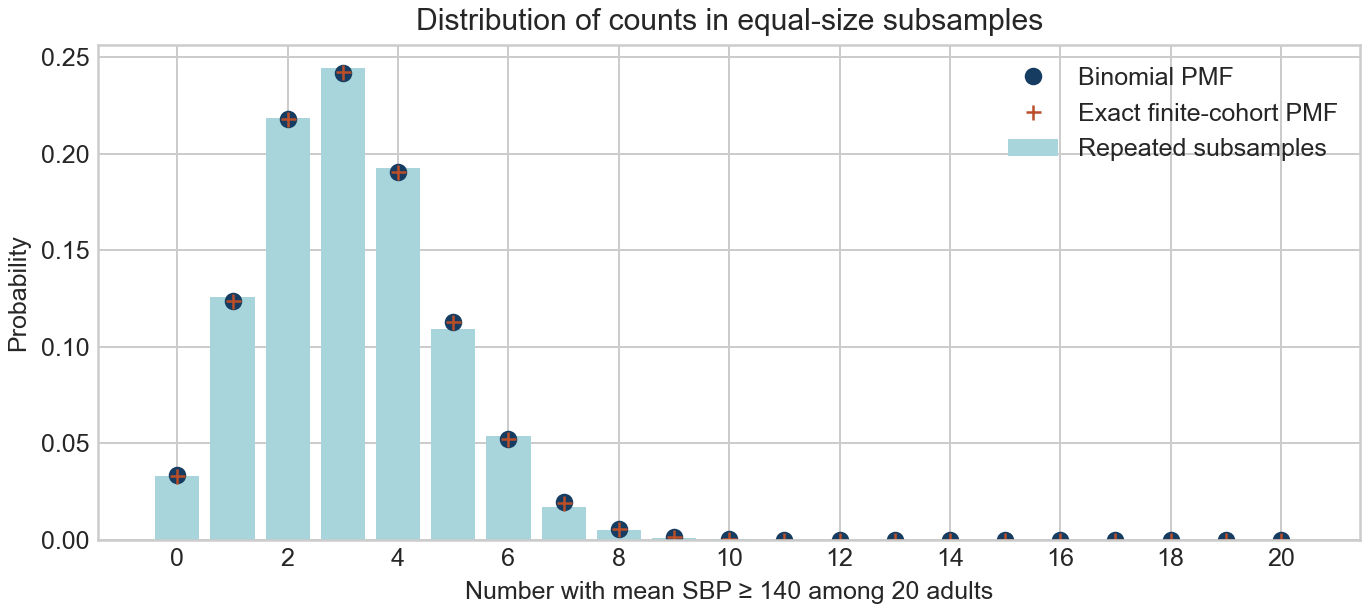

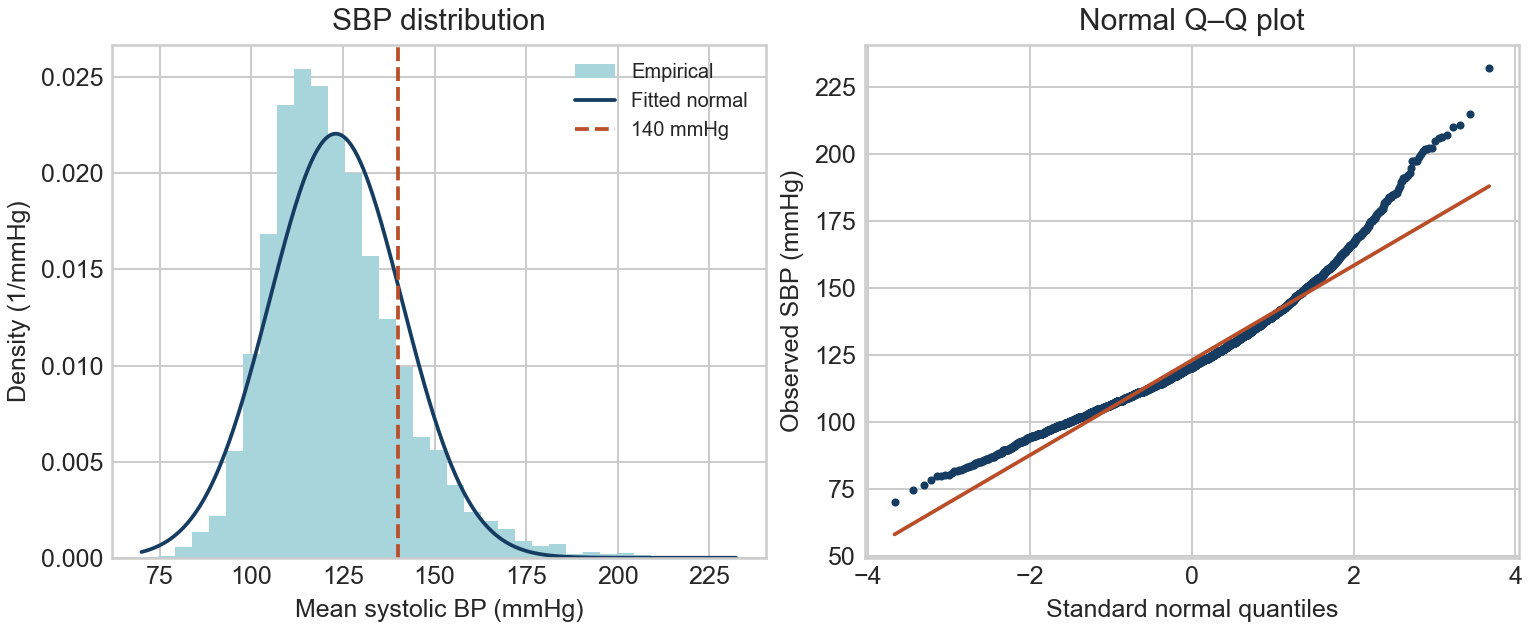

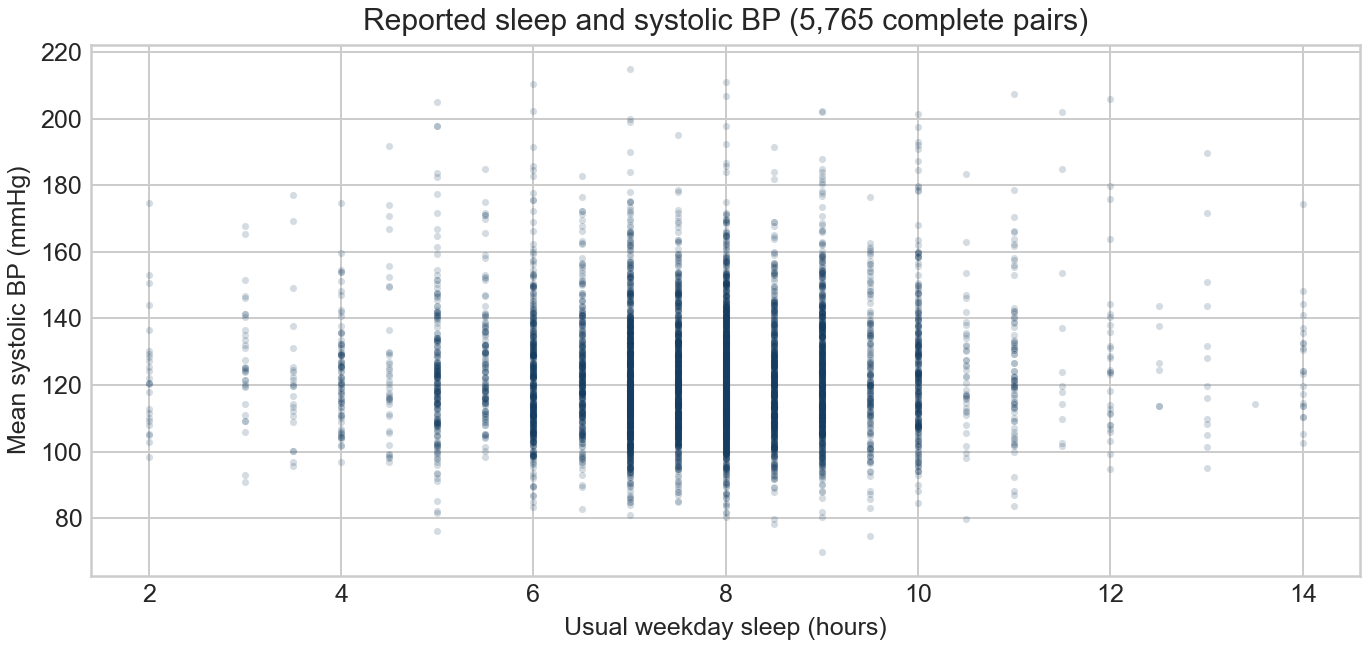

In [3]:
display(pmf.round(5), summary.iloc[13:])
for name in ["binomial.png", "normal.png", "sleep_sbp.png"]:
    display(Image(filename=str(FIGURES / name), width=720))